# Assignment 04 | Student Pass/Fail Prediction

## 1. Inspect the data and choose features

Predict `passed` (0 = Fail, 1 = Pass) using study hours, attendance, practice tests, sleep hours and study method. These are treated as values available before the final result. Leave out `final_score` because it reveals information about the outcome.

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

students = pd.read_csv("student_learning.csv")
print(students.head().to_string(index=False))
print("Rows and columns:", students.shape)
print("Column types:")
print(students.dtypes.to_string())
print("Missing values:")
print(students.isna().sum().to_string())
print("Duplicate rows:", students.duplicated().sum())
print("Target counts (0 = Fail, 1 = Pass):")
print(students["passed"].value_counts().sort_index().to_string())
print("Target percentages:")
print(students["passed"].value_counts(normalize=True).sort_index().mul(100).round(1).to_string())
print("Numeric features at a glance:")
print(students[["hours_studied", "attendance", "practice_tests", "sleep_hours"]].describe().round(2))
print("Study methods:")
print(students["study_method"].value_counts().to_string())

 hours_studied  attendance  practice_tests  sleep_hours study_method  final_score  passed
           7.5          54               0          5.6        video           48       0
           4.4          61               0          6.0        video           50       0
           8.2          63               1          5.2        group           73       1
           6.8          64               1          8.4         self           53       0
           1.3          79               5          5.8         self           51       0
Rows and columns: (280, 7)
Column types:
hours_studied     float64
attendance          int64
practice_tests      int64
sleep_hours       float64
study_method       object
final_score         int64
passed              int64
Missing values:
hours_studied     0
attendance        0
practice_tests    0
sleep_hours       0
study_method      0
final_score       0
passed            0
Duplicate rows: 0
Target counts (0 = Fail, 1 = Pass):
passed
0    157
1    123
Ta

## 2. Split the data and define preprocessing

Use 80% for training and 20% for testing. Stratification keeps the Pass/Fail proportions similar in both sets. The supplied file has no missing values, but the pipelines can still handle blank numeric and categorical fields in future records. Each pipeline learns its medians, common category, and scaling values from the training rows it receives.

In [2]:
number_columns = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]
category_columns = ["study_method"]
feature_columns = number_columns + category_columns

student_features = students[feature_columns]
pass_labels = students["passed"]

study_train, study_test, pass_train, pass_test = train_test_split(
    student_features, pass_labels, test_size=0.20, random_state=42, stratify=pass_labels
)
print("Training rows:", len(study_train))
print("Test rows:", len(study_test))

def make_student_pipeline(classifier):
    number_steps = Pipeline([
        ("fill_blanks", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    category_steps = Pipeline([
        ("fill_blanks", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ])
    prepare_students = ColumnTransformer([
        ("numbers", number_steps, number_columns),
        ("categories", category_steps, category_columns),
    ])
    return Pipeline([
        ("prepare", prepare_students),
        ("classifier", classifier),
    ])

Training rows: 224
Test rows: 56


## 3. Train the baseline and two candidates

The dummy baseline always predicts the most common training class. Logistic regression gives a simple linear comparison. A random forest can learn nonlinear patterns and interactions. Select the candidate using average Pass-class F1 from five stratified folds of the training data. The held-out test set is used for the final comparison.

In [3]:
classifiers = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
training_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fitted_pipelines = {}
training_f1 = {}

for model_name, classifier in classifiers.items():
    student_pipeline = make_student_pipeline(classifier)
    if model_name != "Dummy baseline":
        fold_scores = cross_val_score(
            student_pipeline, study_train, pass_train, cv=training_folds,
            scoring="f1", error_score="raise"
        )
        training_f1[model_name] = fold_scores.mean()
        print(f"{model_name} mean validation F1: {training_f1[model_name]:.3f}")

    fitted_pipelines[model_name] = student_pipeline.fit(study_train, pass_train)

selected_model = max(training_f1, key=training_f1.get)
print("Selected model:", selected_model)

Logistic regression mean validation F1: 0.797
Random forest mean validation F1: 0.769
Selected model: Logistic regression


## 4. Evaluate every model on the same test set

Accuracy is the share of correct predictions. F1 balances precision and recall for the Pass class. In each matrix, the top-right cell counts actual Fails predicted as Pass. The bottom-left counts actual Passes predicted as Fail.

                     Accuracy  F1 (Pass)  True Fail  False Pass  False Fail  True Pass
Model                                                                                 
Dummy baseline          0.554      0.000         31           0          25          0
Logistic regression     0.750      0.720         24           7           7         18
Random forest           0.768      0.735         25           6           7         18
Logistic regression: 7 false passes and 7 false fails.


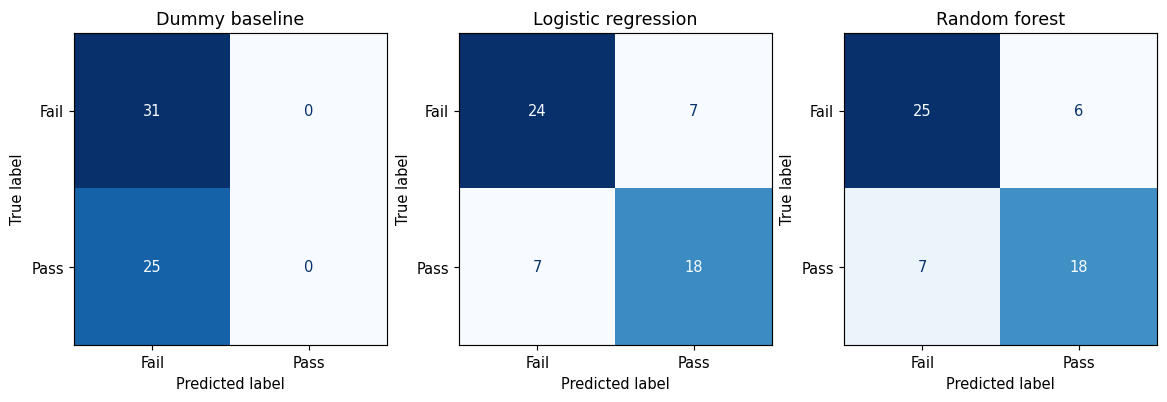

In [4]:
model_results = []
figure, panels = plt.subplots(1, 3, figsize=(11, 3.6), layout="constrained")

for panel, (model_name, student_pipeline) in zip(panels, fitted_pipelines.items()):
    predicted_pass = student_pipeline.predict(study_test)
    matrix = confusion_matrix(pass_test, predicted_pass, labels=[0, 1])
    true_fail, false_pass, false_fail, true_pass = matrix.ravel()

    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(pass_test, predicted_pass),
        "F1 (Pass)": f1_score(pass_test, predicted_pass, zero_division=0),
        "True Fail": true_fail, "False Pass": false_pass,
        "False Fail": false_fail, "True Pass": true_pass,
    })
    ConfusionMatrixDisplay(matrix, display_labels=["Fail", "Pass"]).plot(
        ax=panel, cmap="Blues", colorbar=False
    )
    panel.set_title(model_name)

score_table = pd.DataFrame(model_results).set_index("Model")
print(score_table.round(3).to_string())
chosen_errors = score_table.loc[selected_model]
print(f"{selected_model}: {int(chosen_errors['False Pass'])} false passes and "
      f"{int(chosen_errors['False Fail'])} false fails.")
plt.show()

A false Pass could hide a need for support. A false Fail could wrongly label a student as struggling. These mistakes matter in different ways, so both are reported alongside the scores. The baseline can get some predictions right by always saying Fail, but its Pass-class F1 is zero because it misses every actual Pass.
 
## 5. Save, reload and predict new students

The saved file includes preprocessing and the trained classifier. The demo CSV contains three hand-written examples with no outcome labels. One has a blank sleep value so the saved pipeline can demonstrate imputation. The predicted classes are examples, not measured outcomes.

In [5]:
joblib.dump(fitted_pipelines[selected_model], "student_pipeline.joblib")

loaded_pipeline = joblib.load("student_pipeline.joblib")
new_students = pd.read_csv("new_student_records.csv")
new_predictions = new_students.copy()
new_predictions["predicted_passed"] = loaded_pipeline.predict(new_students[feature_columns])
new_predictions["predicted_outcome"] = new_predictions["predicted_passed"].map({0: "Fail", 1: "Pass"})

print(new_predictions.to_string(index=False))
new_predictions.to_csv("new_student_predictions.csv", index=False)

 hours_studied  attendance  practice_tests  sleep_hours study_method  predicted_passed predicted_outcome
           8.0          94               5          7.5         self                 1              Pass
           1.5          57               0          5.0        video                 0              Fail
           5.0          81               3          NaN        group                 1              Pass


## 6. Streamlit demo

Run `python -m streamlit run app.py` from the project folder. Enter the five feature values and click **Predict**. The app loads the saved pipeline and does not retrain it.

## 7. Limitations and responsible use

This dataset has 280 synthetic rows. Scores describe this split only, and we did not validate the model on another class, school, or time period. A prediction does not explain what caused an outcome. Subgroup fairness is unknown because the file does not contain the information needed for that check. Use this project to learn how classification works. Do not use the predictions for grading, ranking, admissions, or penalties.